In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas as pd
import h5py
from typing import Literal
import struct

plt.rcParams["figure.dpi"] = 500

In [2]:
def plot_with_peaks(
    data,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None,
    text_size=5,
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    bottom = np.zeros(n_bins)

    for signal in signals:
        counts, bins = np.histogram(signal, bins=n_bins, density=False, range=bin_range)
        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        plt.bar(bin_centers, counts, width=bin_width, align="center", bottom=bottom)
        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(bin_centers[peaks], counts[peaks], half_widths):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=2,
                    elinewidth=0.2,
                    capthick=0.2,
                )
                plt.annotate(
                    f"{x:.03f} ± {half_width:.03f} MeV",
                    (x, y + height_scale * (0.005 * text_size)),
                    ha="left",
                    fontsize=text_size,
                )

    plt.xlabel(xlabel)
    plt.ylabel("Count")
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    plt.show()

# Loaders

In [9]:
keys = [
    "Edep",
    "sourceDepth",
    "sourceRadius",
    "sourceE",
    # "sourcePDG",
    # "sourceE"
]

def decode(b):
    return b.decode("utf-8")

decode_v = np.vectorize(decode)


def load_hdf5(path):
    dfs = []
    with h5py.File(path, "r") as f:
        for key in keys:
            data = f["default_ntuples"]["Measurement"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)

            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)


def load_csv(path):
    df = pd.read_csv(path, comment="#", header=None)
    df.columns = keys.copy()
    print(f"{df.shape[0]:,} interactions recorded")
    return df


def load_raw(path):
    rows = []
    with open(path, "rb") as file:
        while data := file.read(3 * 8):
            energy, p_z, depth = struct.unpack("ddd", data)
            rows.append([energy, p_z, depth])
    df = pd.DataFrame(rows, columns=["E", "p_z", "z"])
    return df

In [10]:
df = load_csv("archive/pulses.csv")
df

1,217,766 interactions recorded


,Edep,sourceDepth,sourceRadius,sourceE
0,7.115150,-61.30470,571.1180,7.115150
1,0.104817,-69.78240,267.6380,0.693363
2,0.392883,-4.43075,72.2542,0.510999
3,0.174890,-183.25800,325.7640,1.237470
4,0.065295,-150.53200,369.8090,1.967350
...,...,...,...,...
1217761,0.657914,-94.58190,495.4390,0.657914
1217762,0.188301,-319.42700,363.1990,0.423864
1217763,0.044358,-109.19700,581.7370,5.193610
1217764,0.342810,-13.61330,355.3690,0.342810


# Analysis

## Masking Utilities

In [11]:
property_range = lambda property, lower, upper, mask=None: (
    df if mask is None else df[mask]
)[property].between(lower, upper)
energy_range = lambda lower, upper, mask=None: property_range("Edep", lower, upper, mask)
include_particles = lambda names, mask=None: (df if mask is None else df[mask])[
    "name"
].isin(names)
exclude_particles = lambda names, mask=None: ~(df if mask is None else df[mask])[
    "name"
].isin(names)

## Energy Spectrum

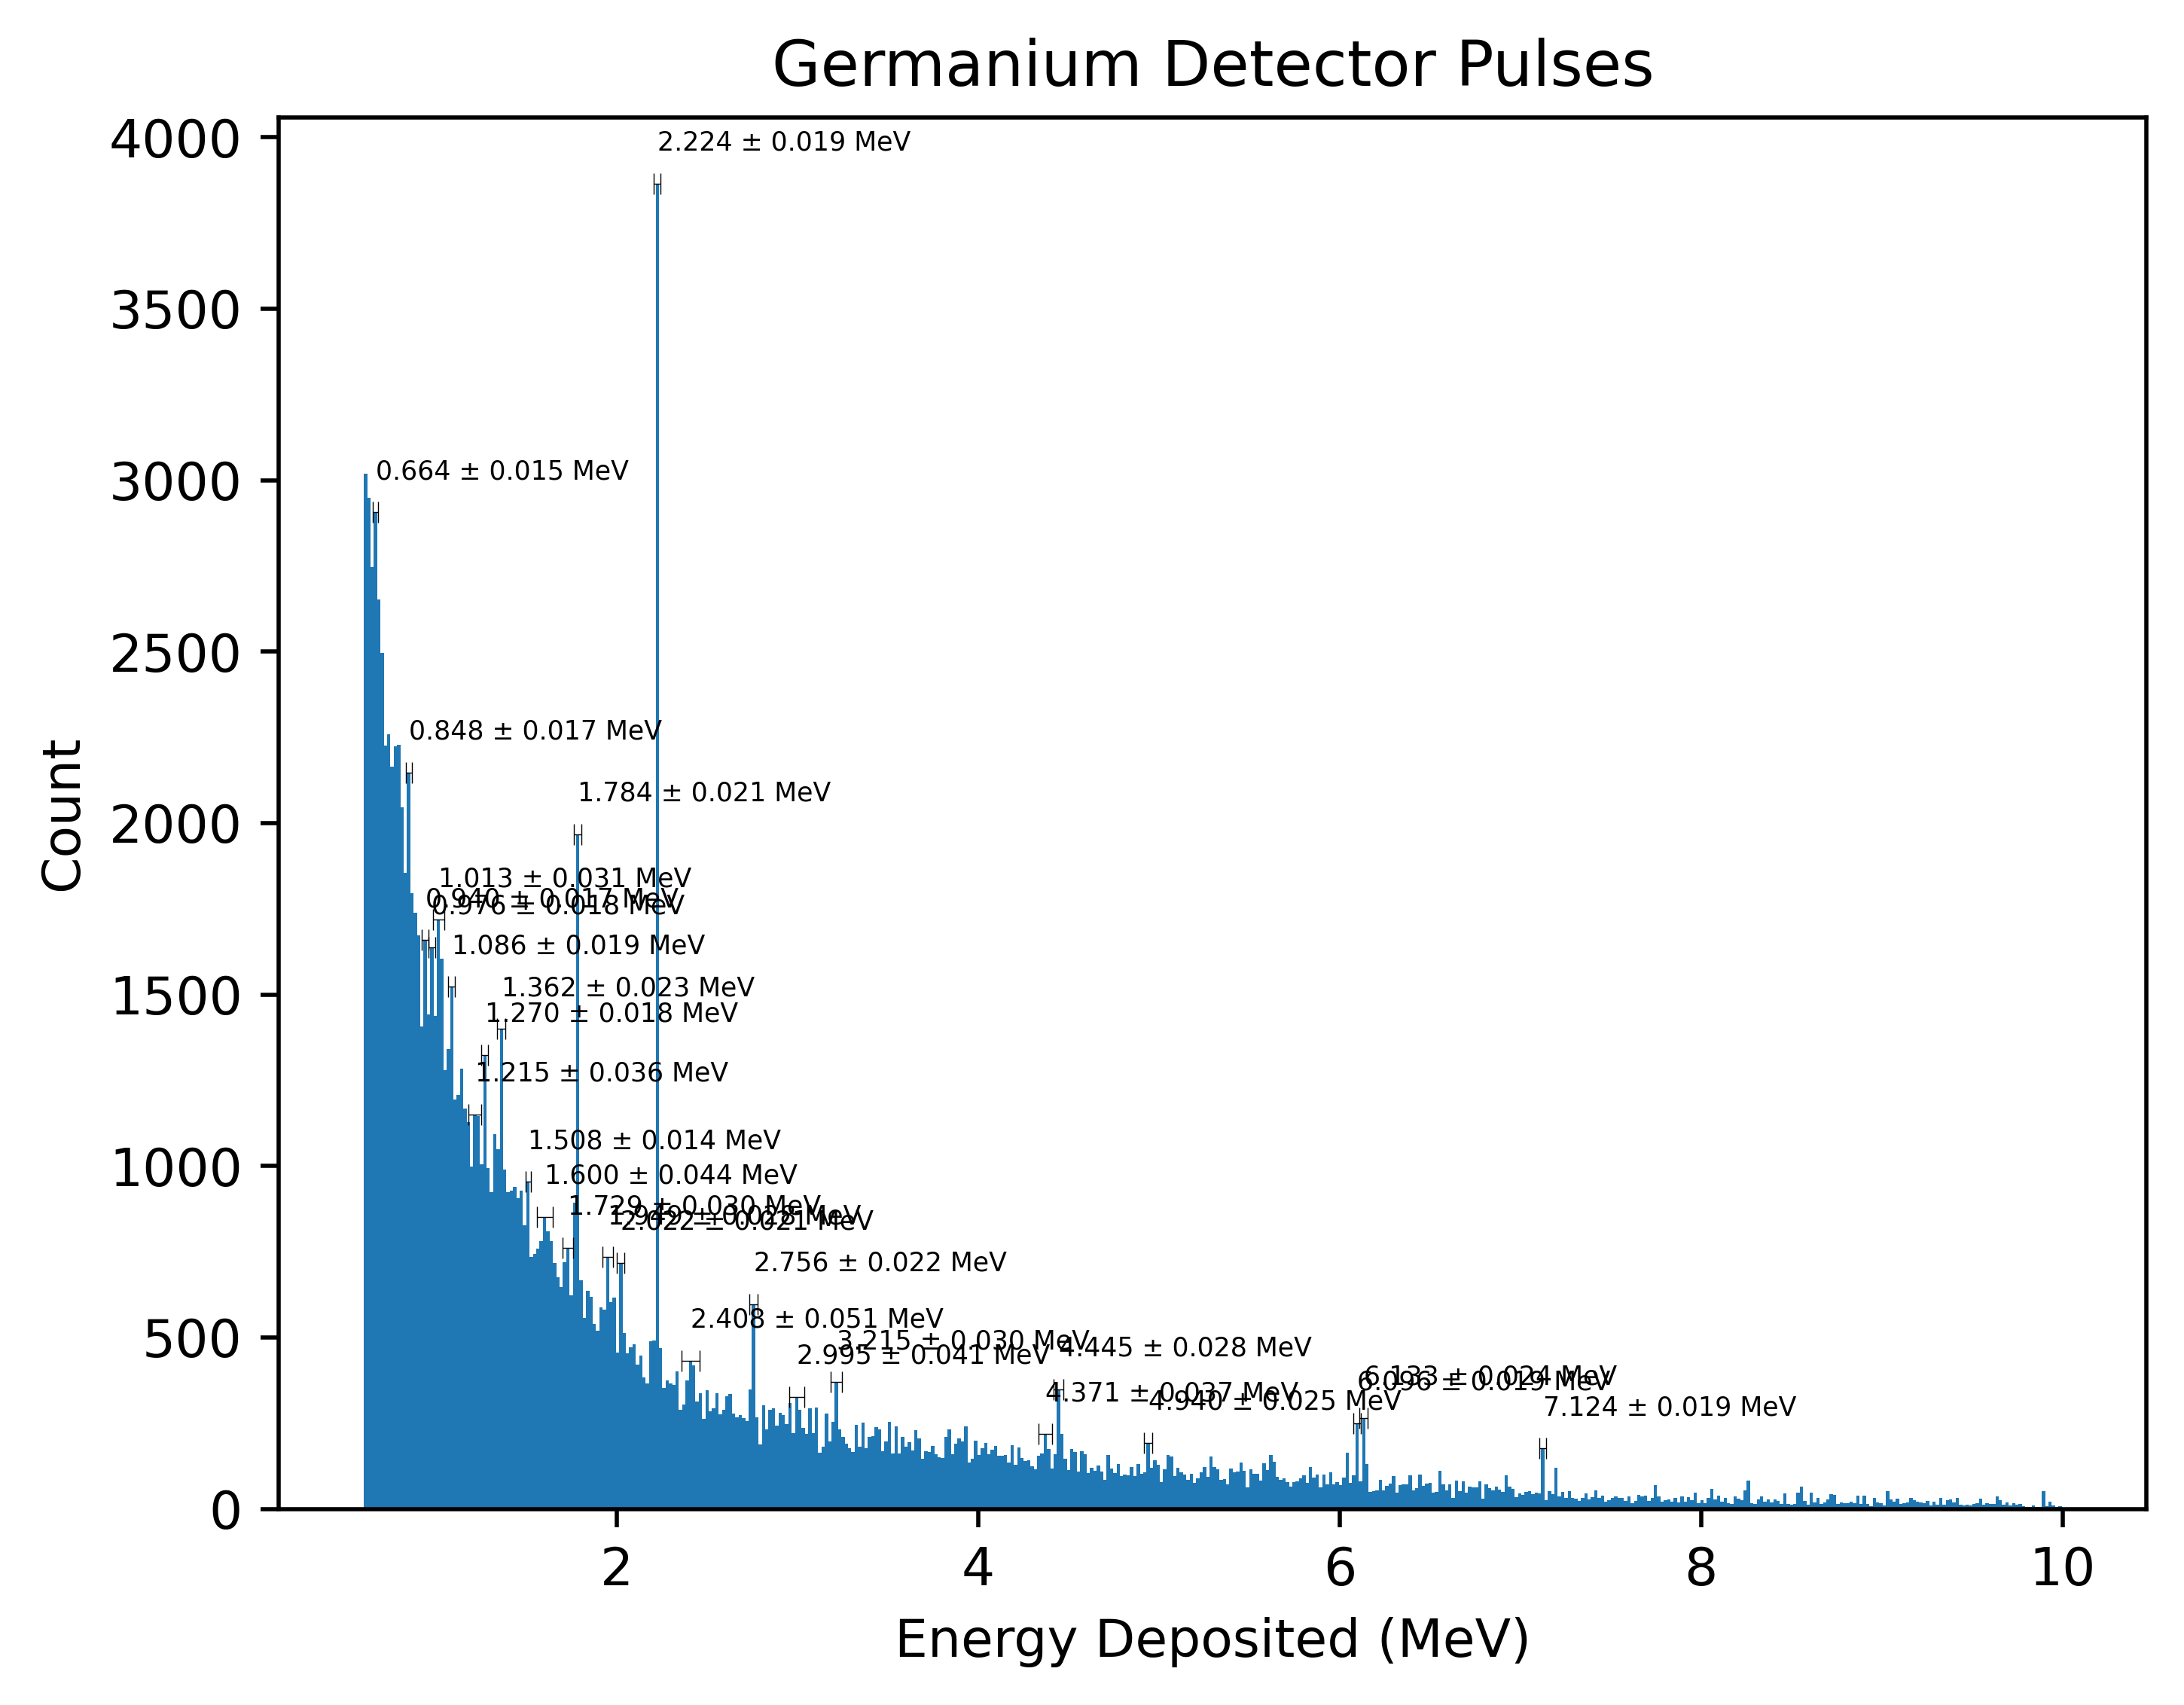

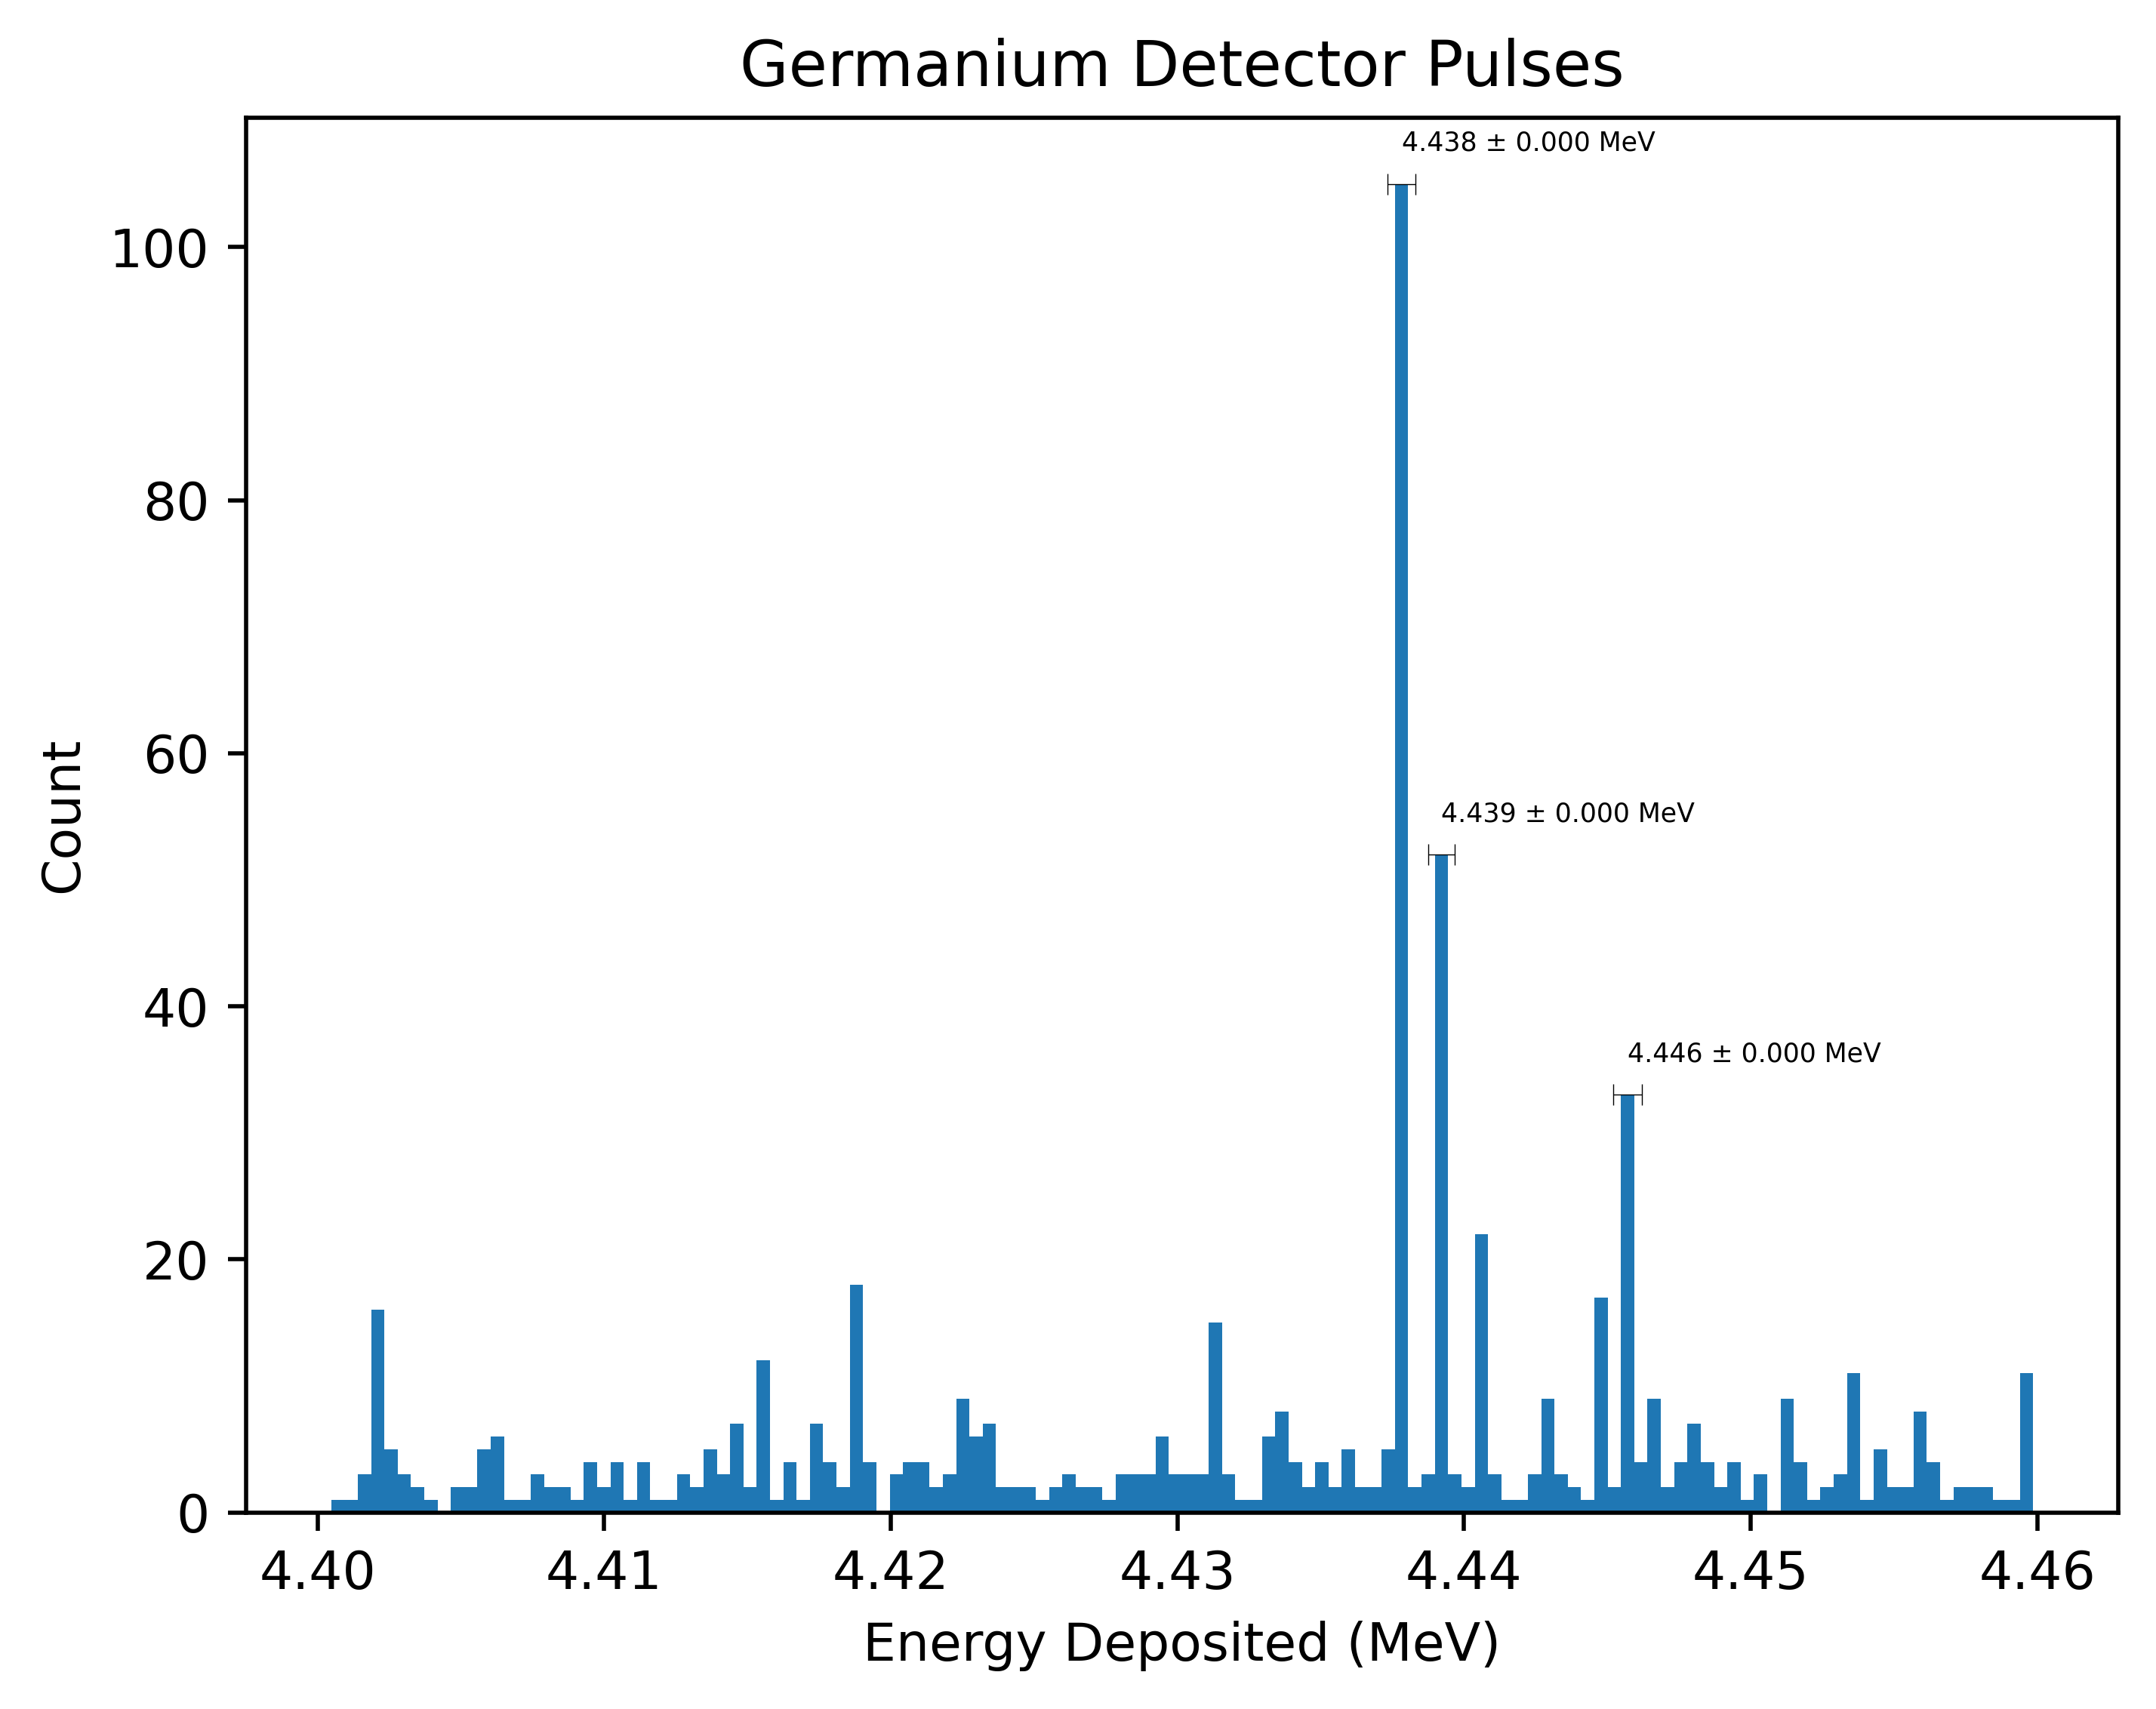

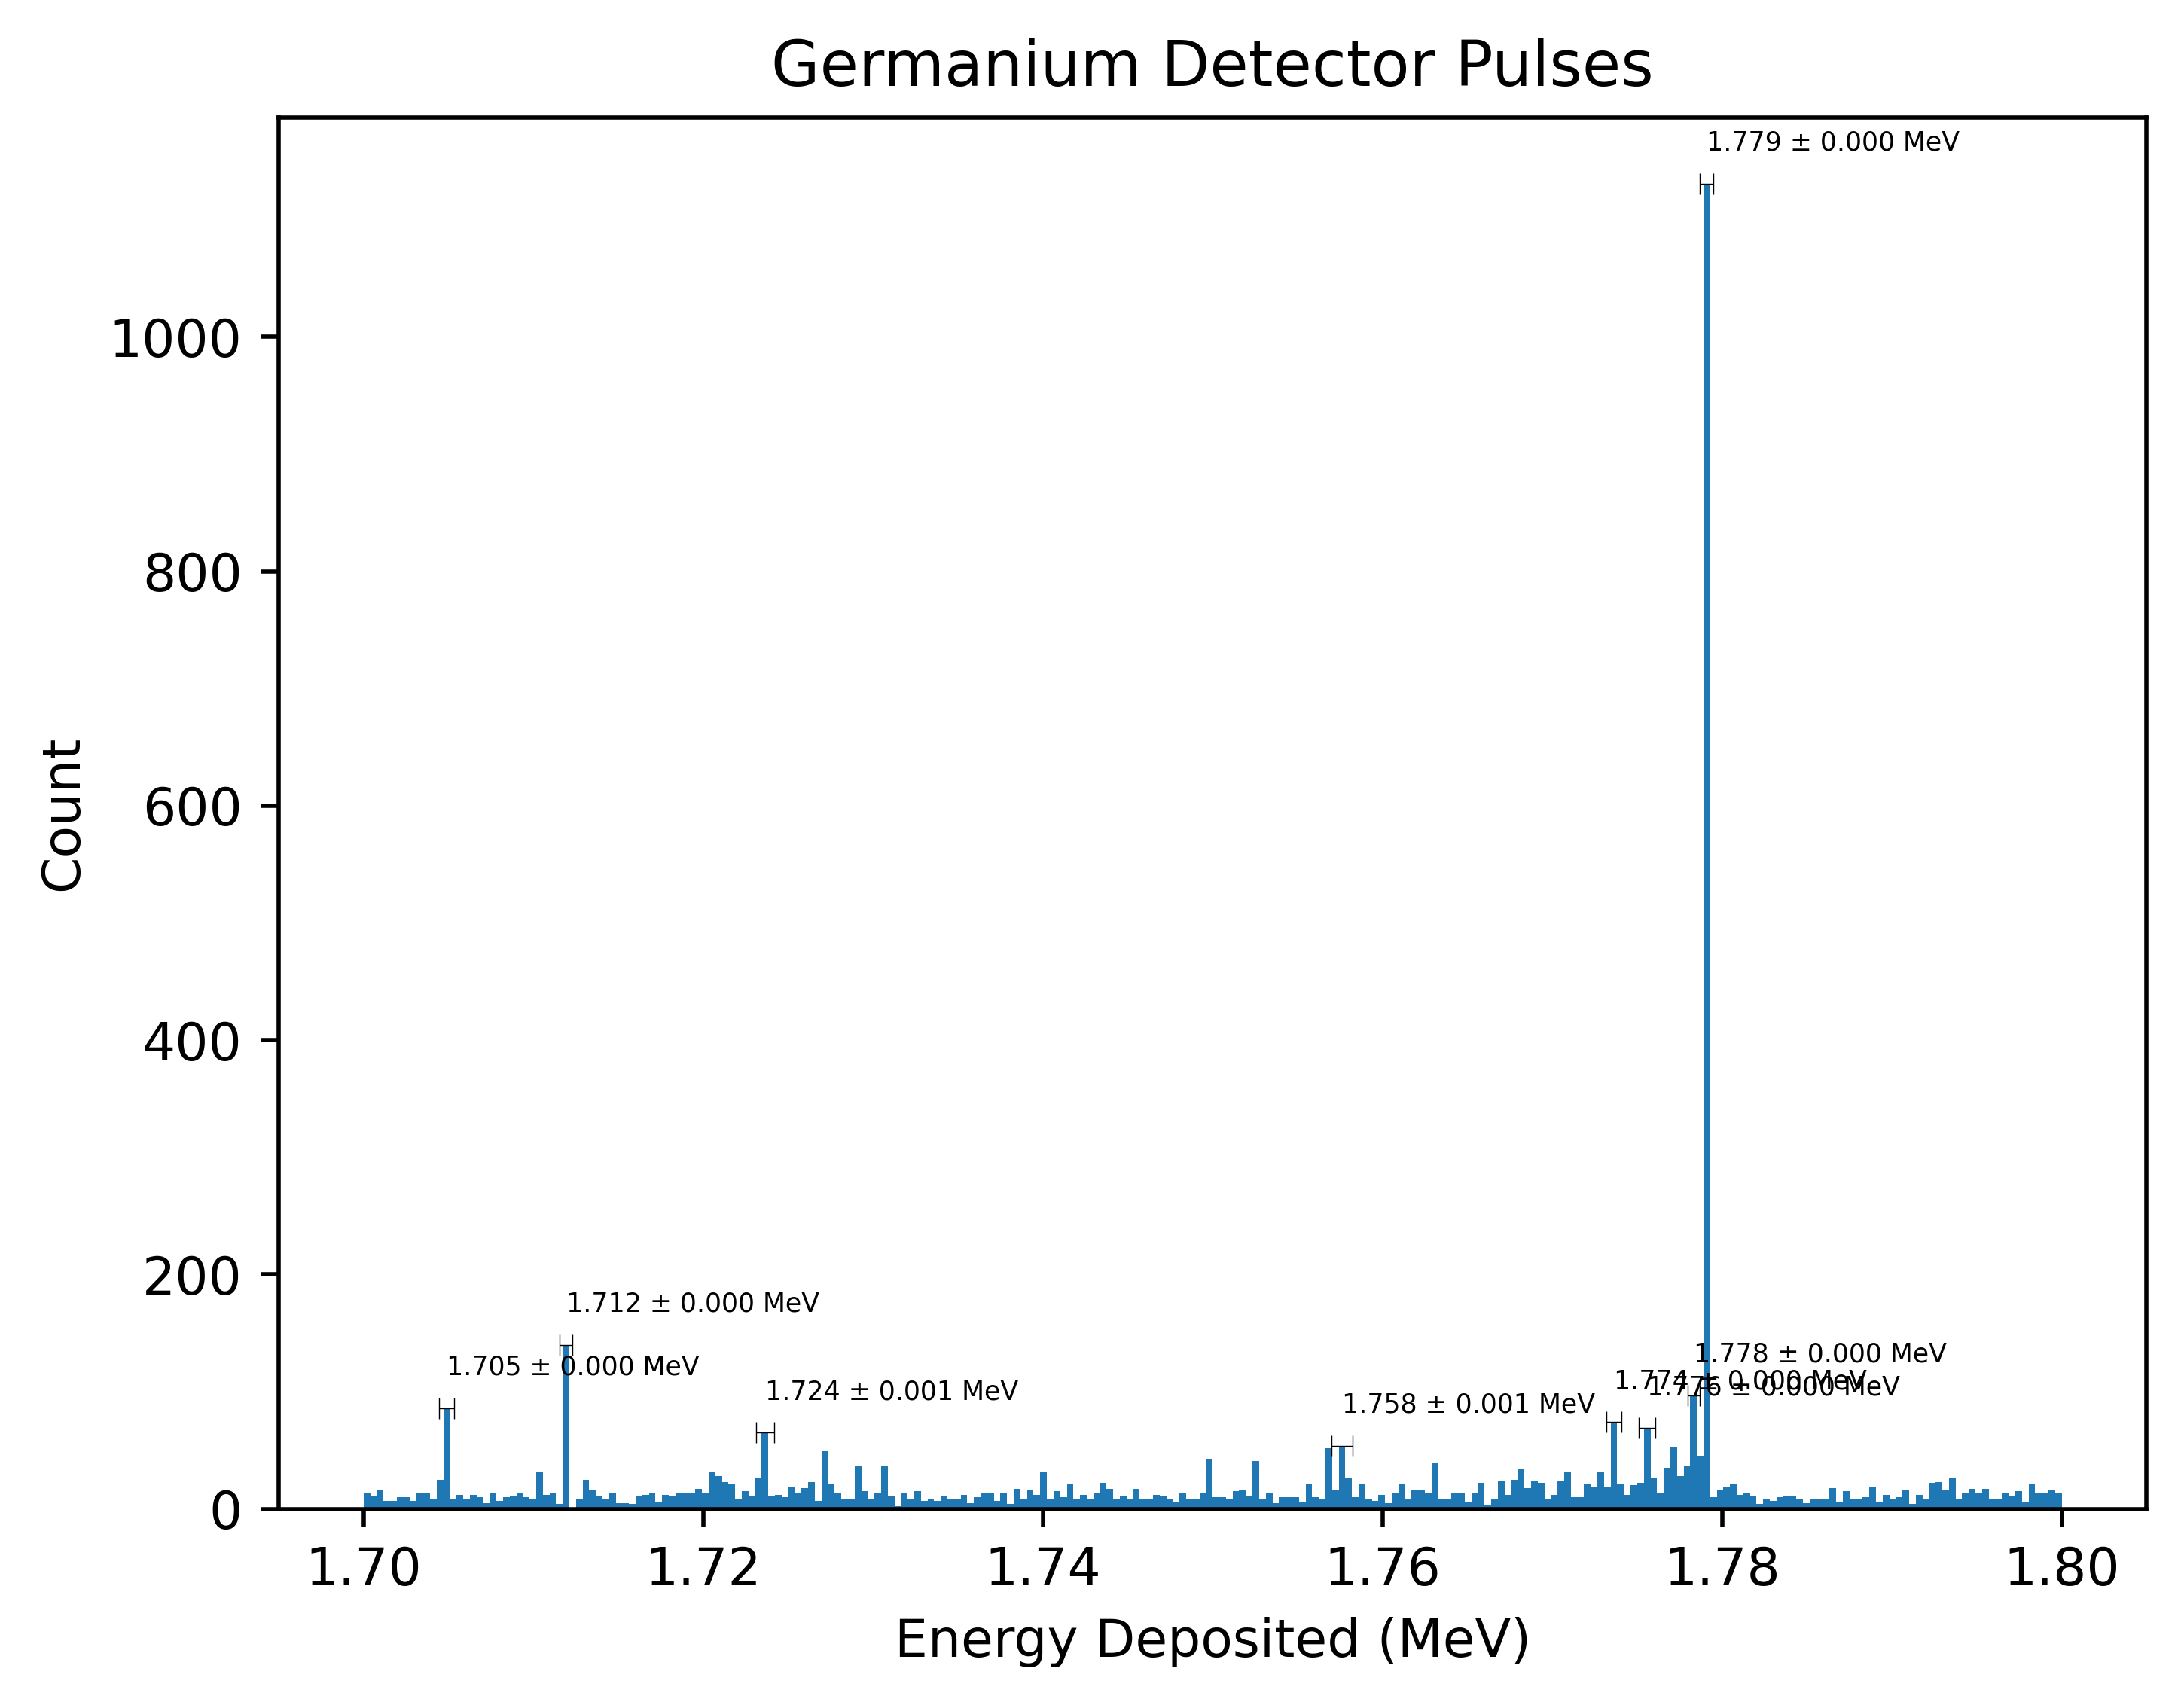

In [15]:
def plot_energy_spectrum(
    e_low, e_high, n_bins=512, prominence=None, clip=None, text_size=5
):
    energies = df[energy_range(e_low, e_high)]["Edep"]
    plot_with_peaks(
        data=energies,
        n_bins=n_bins,
        prominence=prominence,
        xlabel="Energy Deposited (MeV)",
        title="Germanium Detector Pulses",
        clip_counts=clip,
        text_size=text_size,
    )


plot_energy_spectrum(0.6, 10, n_bins=512, prominence=100)
plot_energy_spectrum(4.4, 4.46, n_bins=128, prominence=30)
plot_energy_spectrum(1.7, 1.8, n_bins=256, prominence=50)

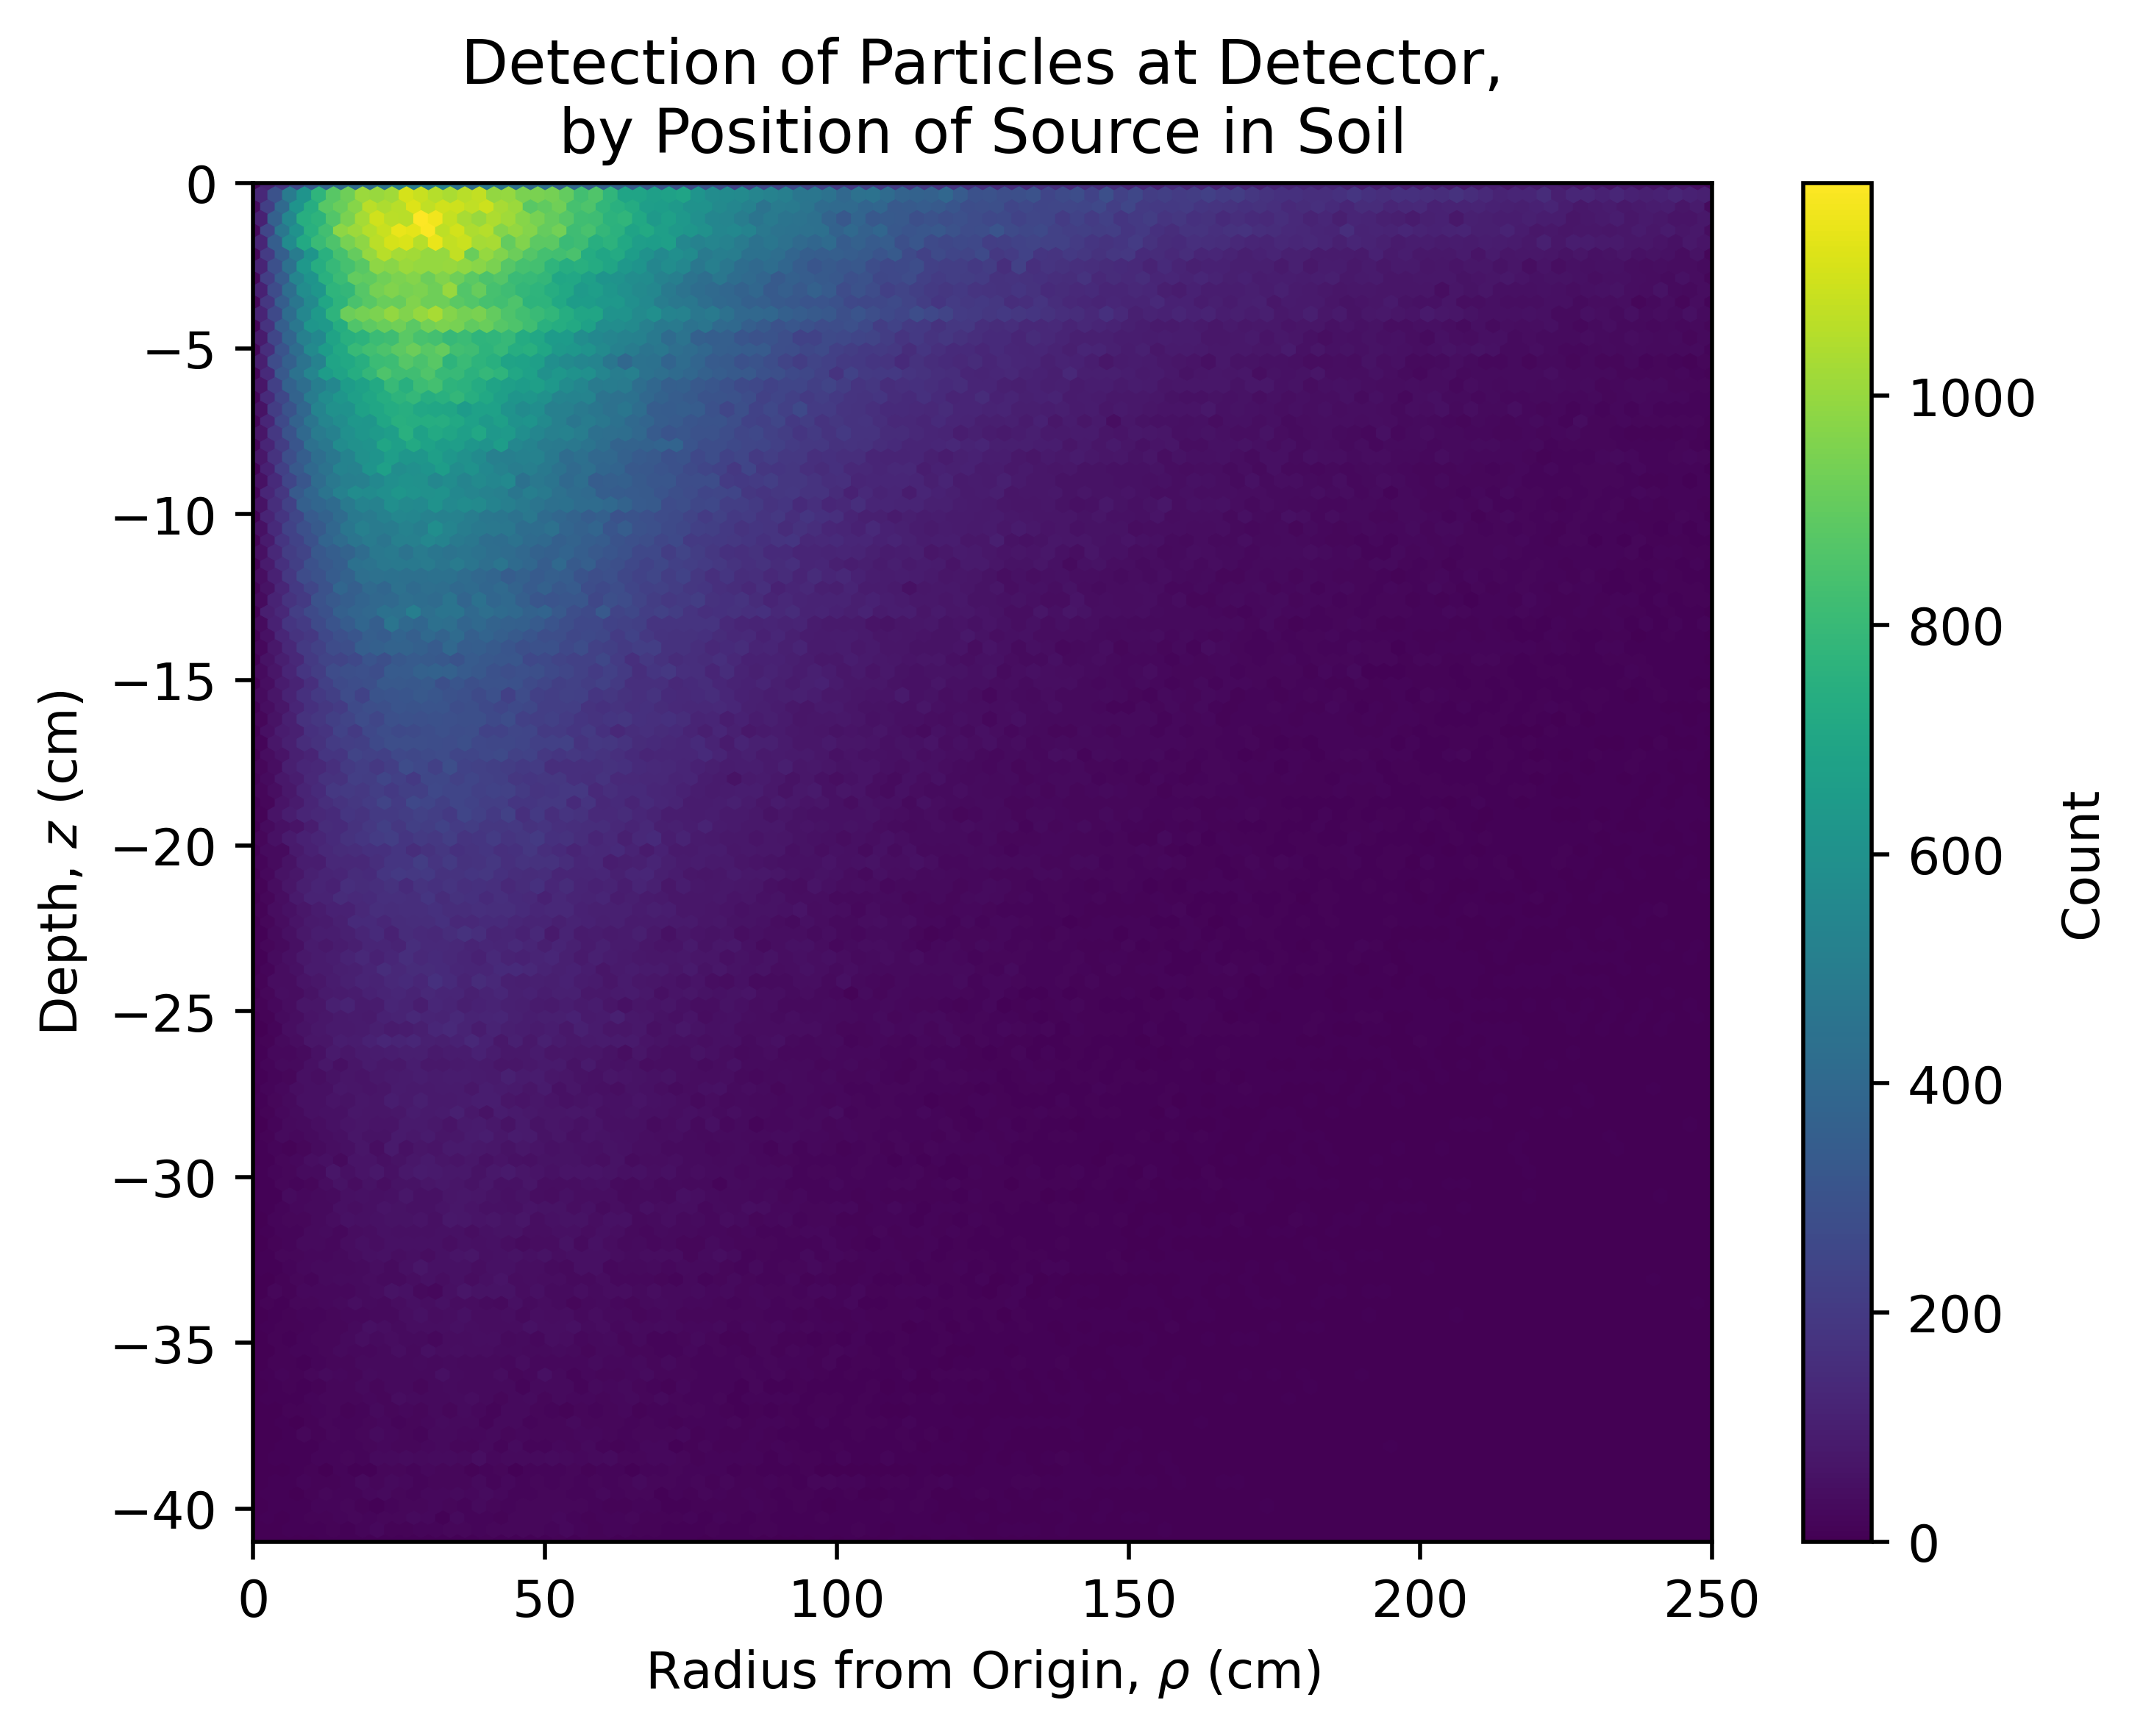

In [13]:
plt.hexbin(
    df["sourceRadius"] / 10,
    df["sourceDepth"] / 10,
    # C=df["Edep"],
    # reduce_C_function=np.sum,
    linewidths=0.2,
    # vmax=0.5,
    # norm=LogNorm(),
)
plt.colorbar(label="Count")
plt.xlabel("Radius from Origin, $\\rho$ (cm)")
plt.ylabel("Depth, $z$ (cm)")
plt.title("Detection of Particles at Detector,\nby Position of Source in Soil")
plt.xlim(0,250)
plt.ylim(-41,0)
plt.show()

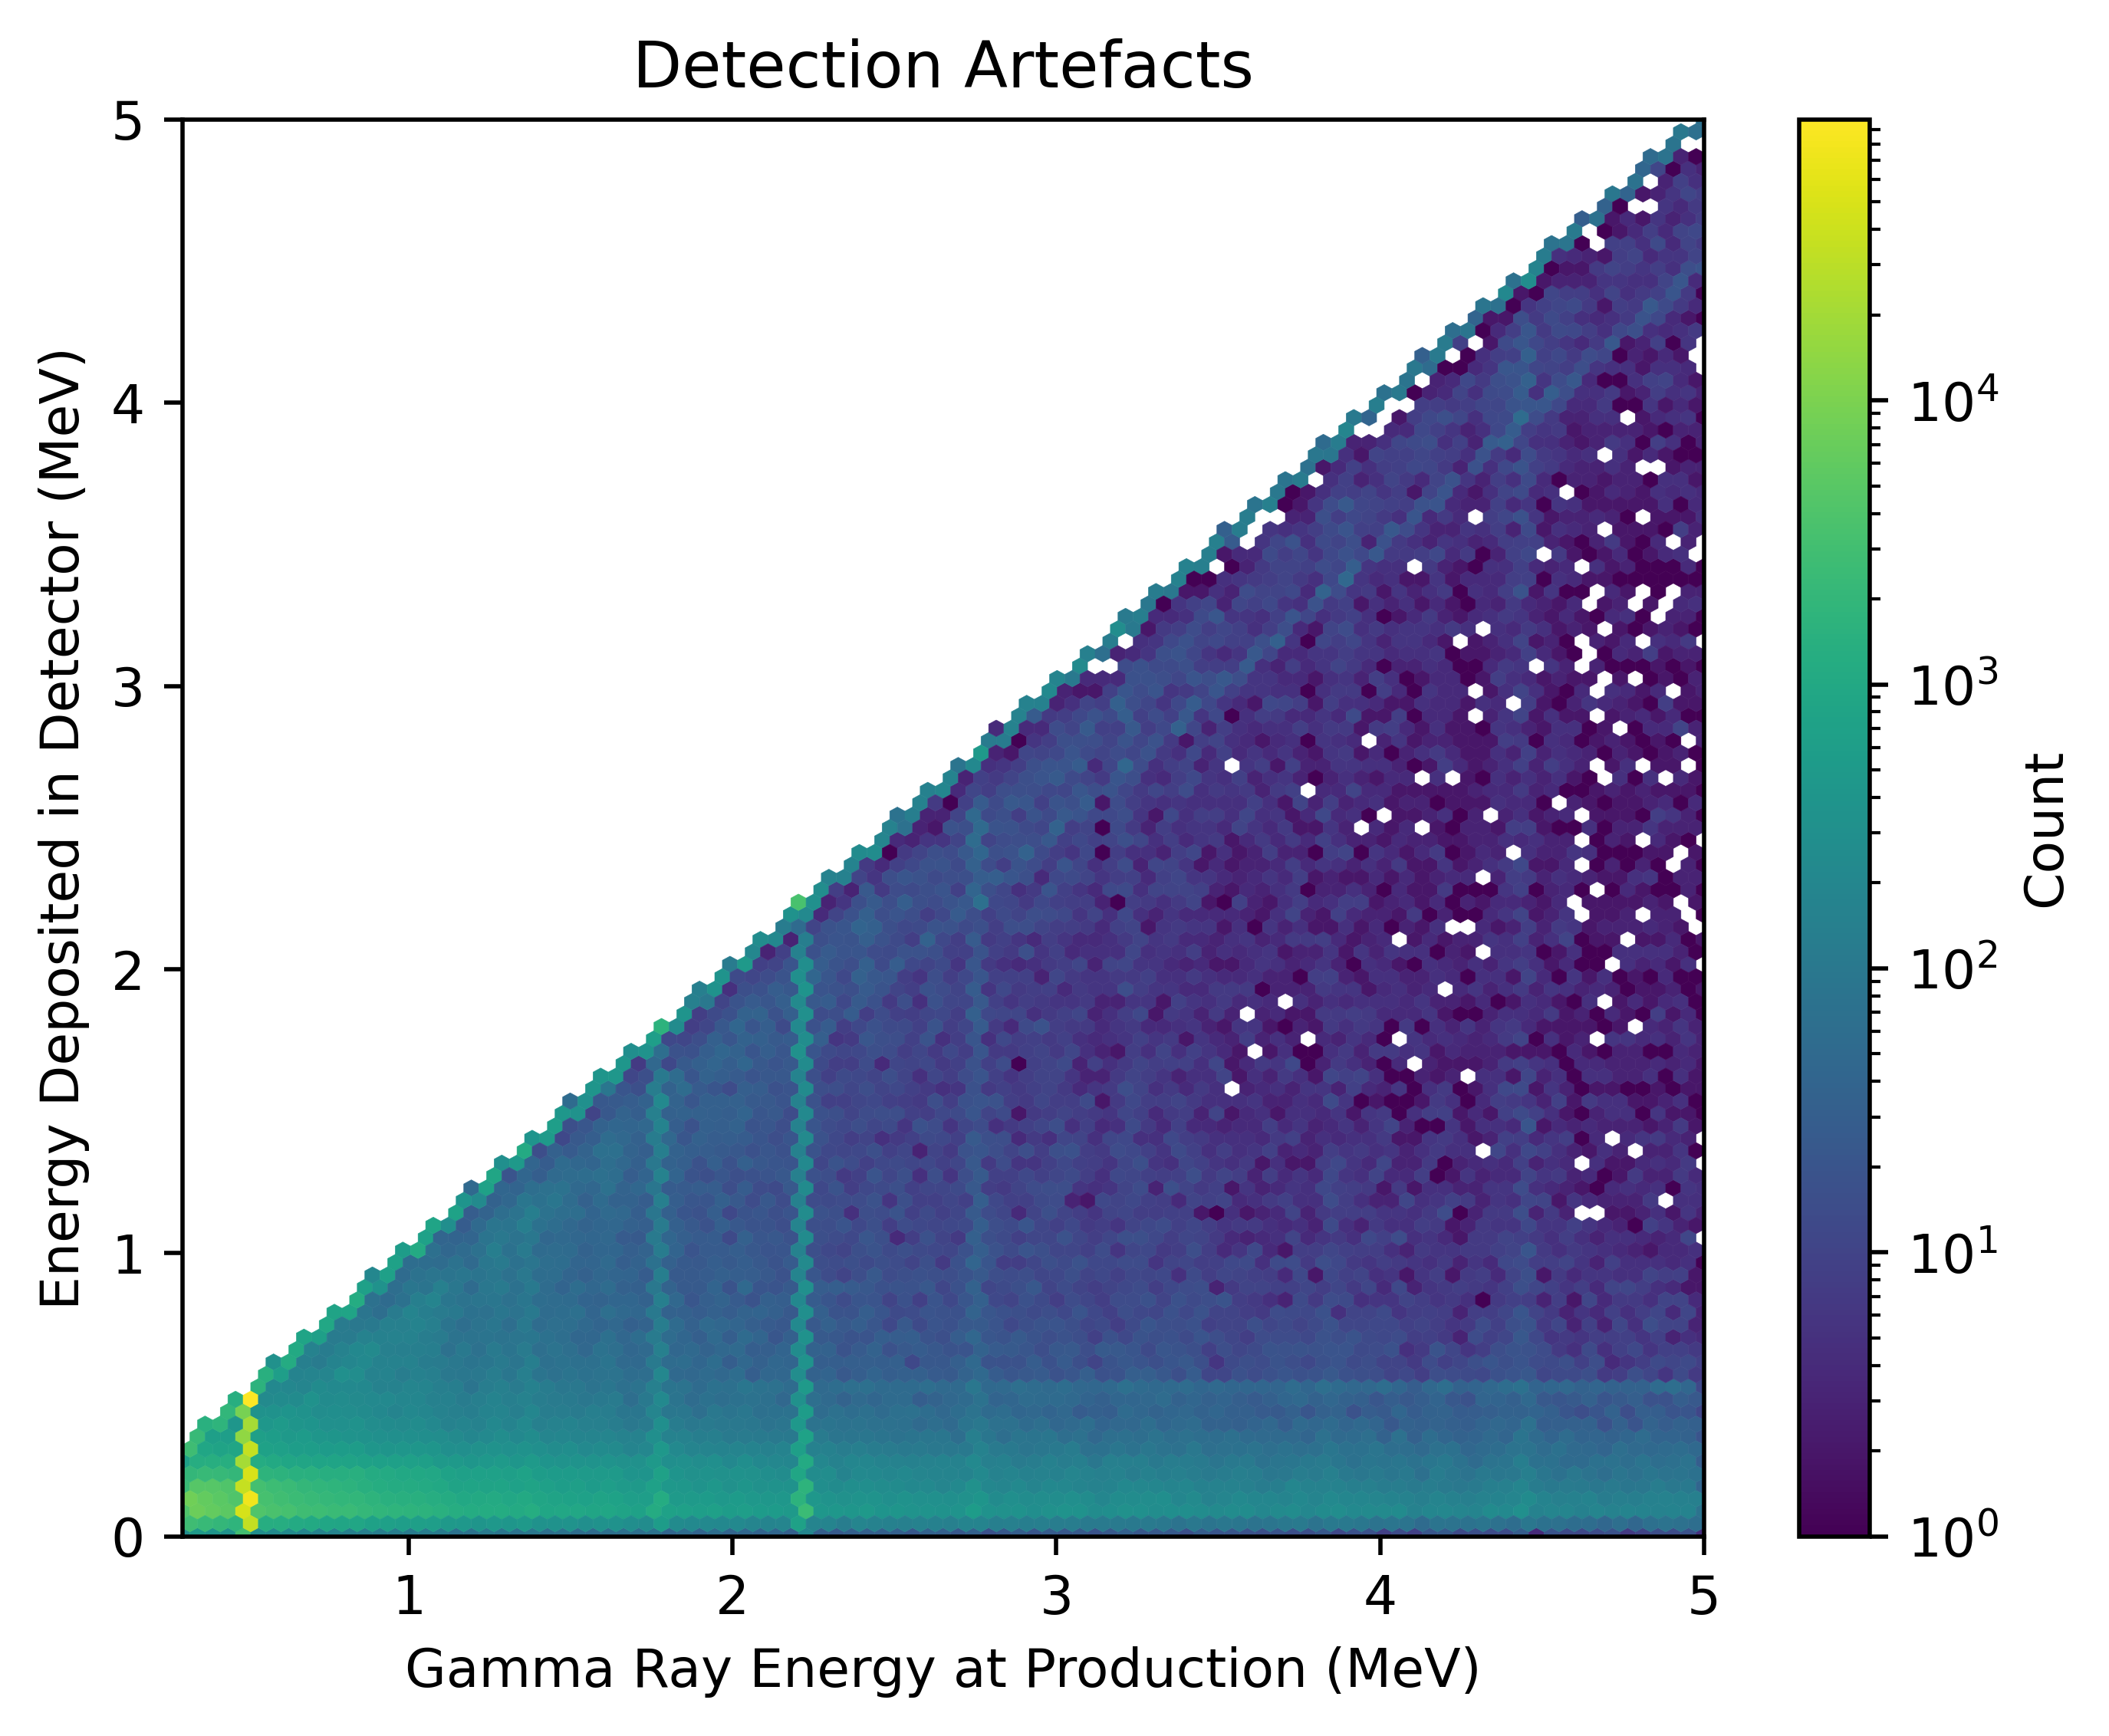

In [16]:
mask = df["sourceE"].between(0.0, 5.0)
plt.hexbin(
    df[mask]["sourceE"],
    df[mask]["Edep"],
    # C=df["Edep"],
    # reduce_C_function=np.sum,
    linewidths=0.08,
    # vmax=100,
    norm=LogNorm(),
)
plt.colorbar(label="Count")
plt.xlabel("Gamma Ray Energy at Production (MeV)")
plt.ylabel("Energy Deposited in Detector (MeV)")
plt.xlim(0.3, 5.0)
plt.ylim(0, 5.0)
plt.title("Detection Artefacts")
plt.show()